<a href="https://colab.research.google.com/github/harshalighadi/MLT/blob/main/MLT5th.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder #
from sklearn import tree #
from sklearn.tree import DecisionTreeClassifier

In [4]:
df=pd.read_csv('/content/drive/MyDrive/Databases/Data/Copy of play_tennis.csv')

In [6]:
df.head()

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes


In [7]:
le=LabelEncoder()
df['outlook_n']=le.fit_transform(df['outlook'])
df['temp_n']=le.fit_transform(df['temp'])
df['humidity_n']=le.fit_transform(df['humidity'])
df['wind_n']=le.fit_transform(df['wind'])
df['play_n']=le.fit_transform(df['play'])

In [8]:
df

,day,outlook,temp,humidity,wind,play,outlook_n,temp_n,humidity_n,wind_n,play_n
0,D1,Sunny,Hot,High,Weak,No,2,1,0,1,0
1,D2,Sunny,Hot,High,Strong,No,2,1,0,0,0
2,D3,Overcast,Hot,High,Weak,Yes,0,1,0,1,1
3,D4,Rain,Mild,High,Weak,Yes,1,2,0,1,1
4,D5,Rain,Cool,Normal,Weak,Yes,1,0,1,1,1
5,D6,Rain,Cool,Normal,Strong,No,1,0,1,0,0
6,D7,Overcast,Cool,Normal,Strong,Yes,0,0,1,0,1
7,D8,Sunny,Mild,High,Weak,No,2,2,0,1,0
8,D9,Sunny,Cool,Normal,Weak,Yes,2,0,1,1,1
9,D10,Rain,Mild,Normal,Weak,Yes,1,2,1,1,1


In [10]:
df=df.drop(['outlook','temp','humidity','wind','play'],axis='columns')

In [11]:
df

,day,outlook_n,temp_n,humidity_n,wind_n,play_n
0,D1,2,1,0,1,0
1,D2,2,1,0,0,0
2,D3,0,1,0,1,1
3,D4,1,2,0,1,1
4,D5,1,0,1,1,1
5,D6,1,0,1,0,0
6,D7,0,0,1,0,1
7,D8,2,2,0,1,0
8,D9,2,0,1,1,1
9,D10,1,2,1,1,1


In [12]:
from sklearn import tree #
from sklearn.tree import DecisionTreeRegressor

In [14]:
independant_variable=df.drop(['play_n','day'],axis='columns')#X
independant_variable=independant_variable.astype(float)
dependant_variable=df['play_n']#Y

In [15]:
model=tree.DecisionTreeClassifier()
#It is used to create an instance of decision tree classifier in scikit-learn

In [16]:
model.fit(independant_variable,dependant_variable)
#fit method in machine learning is used to train a model on given dataset

DecisionTreeClassifier()

In [17]:
model.score(independant_variable,dependant_variable)

1.0

In [18]:
model.predict([[1,2,0,1]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix

In [20]:
#Split Data into 70% train and 30% test
X_train,X_test,y_train,y_test=train_test_split(independant_variable,dependant_variable,test_size=0.3,random_state=42)

In [21]:
#Train the model on training data
model=tree.DecisionTreeClassifier()
model.fit(X_train,y_train)

DecisionTreeClassifier()

In [22]:
#Predict on test data
y_pred=model.predict(X_test)

In [23]:
#Evaluate accuracy
accuracy=accuracy_score(y_test,y_pred)
print(f'Accuracy on test data:{accuracy:.2f}')

Accuracy on test data:0.60


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

#Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred))

#Classification report
print("\nClassification Report:")
print(classification_report(y_test,y_pred))


Confusion Matrix:
[[1 1]
 [1 2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.67      0.67      0.67         3

    accuracy                           0.60         5
   macro avg       0.58      0.58      0.58         5
weighted avg       0.60      0.60      0.60         5



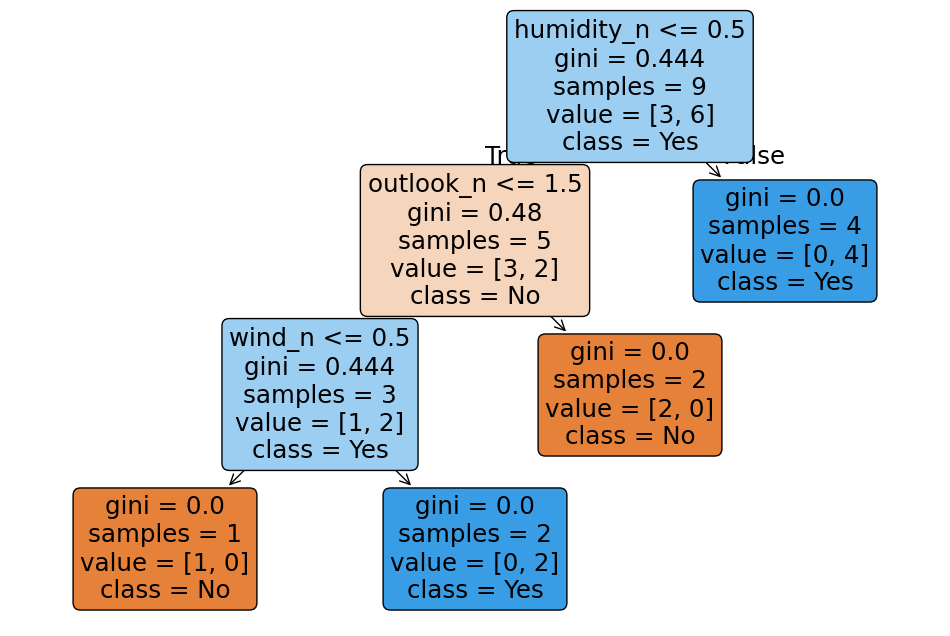

In [26]:
plt.figure(figsize=(12,8))
tree.plot_tree(model,
               feature_names=independant_variable.columns,
               class_names=['No', 'Yes'],
               filled=True,
               rounded=True)
plt.show()

In [27]:
# Displaying the decision tree rules as simple text
from sklearn.tree import export_text

rules = export_text(model, feature_names=list(independant_variable.columns))
print(rules)

|--- humidity_n <= 0.50
|   |--- outlook_n <= 1.50
|   |   |--- wind_n <= 0.50
|   |   |   |--- class: 0
|   |   |--- wind_n >  0.50
|   |   |   |--- class: 1
|   |--- outlook_n >  1.50
|   |   |--- class: 0
|--- humidity_n >  0.50
|   |--- class: 1



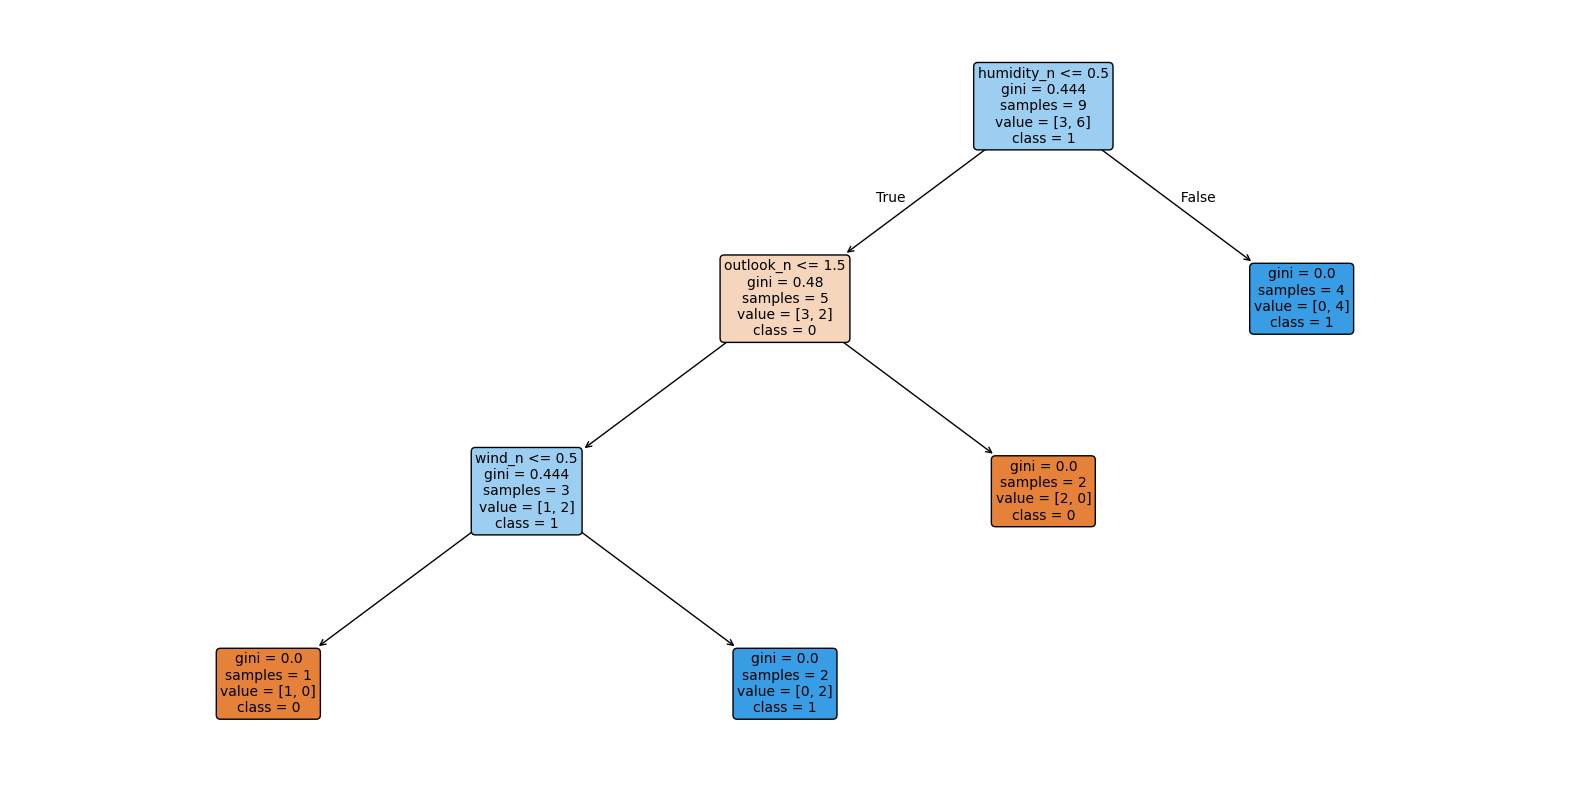

In [31]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    model,                                    # replace with your classifier's variable name
    feature_names=X_train.columns,                  # replace X with your features DataFrame
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()